# Projeto: Implementação do Backpropagation em Python

```
Aluno: Rodrigo Raider de Oliveira
```

Este notebook apresenta o desenvolvimento e teste de um classificador **Multi-Layer Perceptron (MLP)** construído apenas com o Python e NumPy, com o objetivo de compreender os fundamentos do algoritmo de retropropagação (**Backpropagation**).

## Especificações do Projeto

1. **Dataset:** Utilização do dataset *Wine* do Scikit-Learn para classificação de tipos de vinho.
2. **MLP Customizável:** A implementação do MLP deve ser flexível e aceitar parâmetros para definir:
   - A quantidade de camadas ocultas.
   - A quantidade de neurônios em cada camada.
   - A função de ativação que será utilizada em cada camada (ex: Sigmoide, ReLU, Tangente Hiperbólica).
3. **Comparação de Resultados:** Treinar o modelo implementado manualmente e comparar sua acurácia e desempenho com o modelo oficial `MLPClassifier` disponibilizado pela biblioteca **Scikit-Learn**.

## Step 1 - Importação do Dataset

In [19]:
from sklearn.datasets import load_wine
import pandas as pd

# Carregar o dataset
wine = load_wine()

# Organizar os dados em um DataFrame
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="target")

# Visualizar os dados
display(X.head())

print(f"Quantidade de amostras: {X.shape[0]}")
print(f"Quantidade de atributos: {X.shape[1]}")
print(f"Classes: {wine.target_names}")
print(f"Distribuição das classes:\n{y.value_counts().sort_index()}")

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Quantidade de amostras: 178
Quantidade de atributos: 13
Classes: ['class_0' 'class_1' 'class_2']
Distribuição das classes:
target
0    59
1    71
2    48
Name: count, dtype: int64


## Step 2 - Análise Visual dos Dados

Vamos plotar a distribuição das classes e explorar a relação entre algumas das principais variáveis do dataset.

/tmp/ipykernel_2913/4205190808.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(wine.target_names)


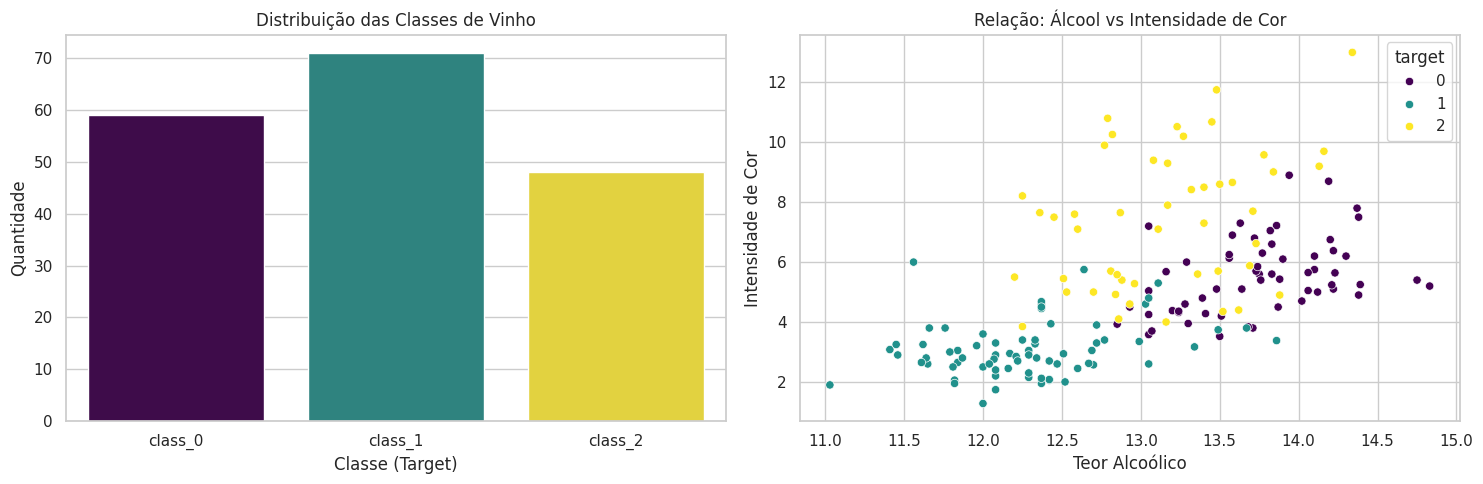

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo dos gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Gráfico de Barras para a distribuição das classes
sns.countplot(x=y, ax=axes[0], palette="viridis", hue=y, legend=False)
axes[0].set_title("Distribuição das Classes de Vinho")
axes[0].set_xlabel("Classe (Target)")
axes[0].set_ylabel("Quantidade")
axes[0].set_xticklabels(wine.target_names)

# 2. Gráfico de dispersão entre Álcool e Intensidade de Cor
sns.scatterplot(x=X["alcohol"], y=X["color_intensity"], hue=y, palette="viridis", ax=axes[1])
axes[1].set_title("Relação: Álcool vs Intensidade de Cor")
axes[1].set_xlabel("Teor Alcoólico")
axes[1].set_ylabel("Intensidade de Cor")

plt.tight_layout()
plt.show()

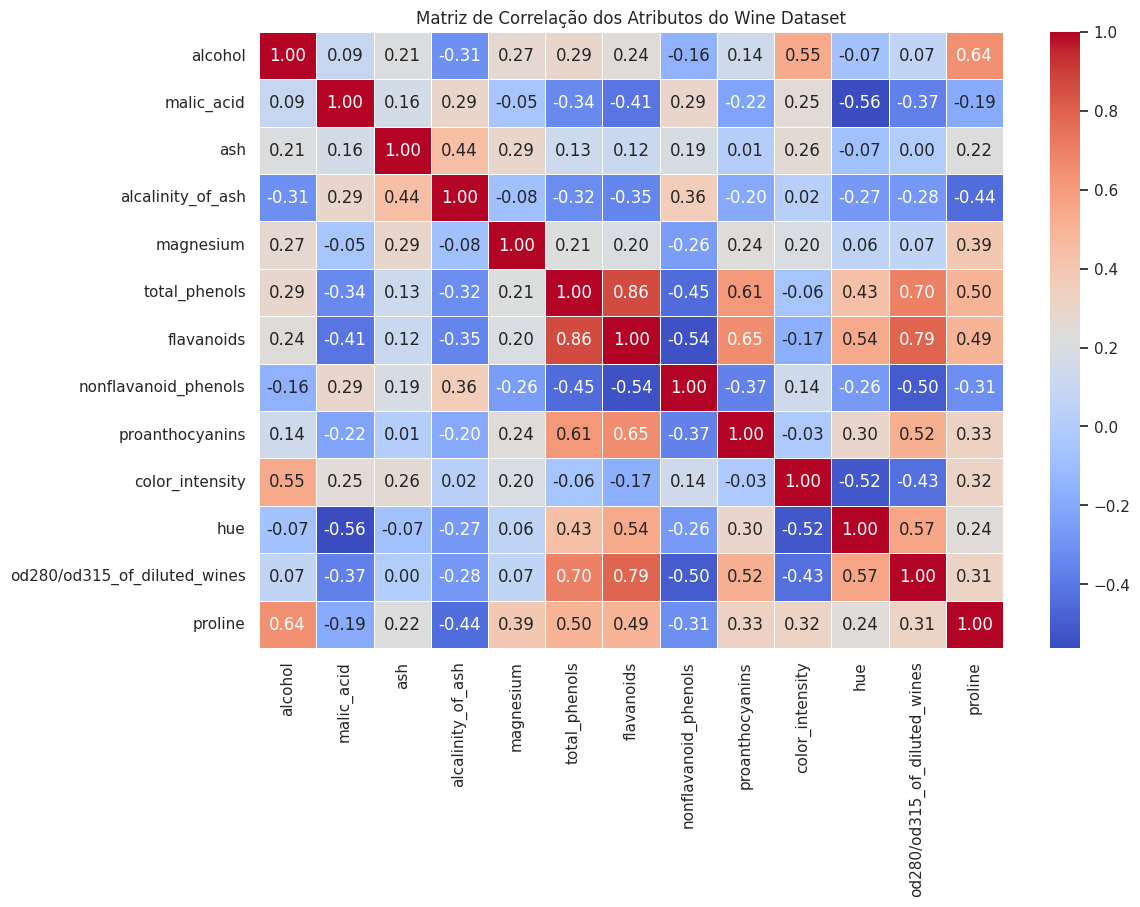

In [21]:
# 3. Matriz de Correlação
plt.figure(figsize=(12, 8))
correlation_matrix = X.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlação dos Atributos do Wine Dataset")
plt.show()

## Step 3 - Preparando o dataset

In [22]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

# Dividir em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalizar os atributos
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Codificar classes em one-hot
encoder = OneHotEncoder(sparse_output=False)
y_train_encoded = encoder.fit_transform(y_train.to_numpy().reshape(-1, 1))

In [23]:
print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_test: {y_test.shape}")

#Print encoder
print(f"Classes: {encoder.categories_[0]}")
print(f"y_train_encoded: {y_train_encoded.shape}")

X_train: (142, 13)
y_train: (142,)
X_test: (36, 13)
y_test: (36,)
Classes: [0 1 2]
y_train_encoded: (142, 3)


##

##Step 4 - Multilayer código

In [24]:
from sklearn.base import BaseEstimator, ClassifierMixin
import numpy as np
from sklearn.preprocessing import OneHotEncoder

def include_bias(X):
    return np.c_[np.ones(X.shape[0]), X]

def softmax(Z):
    Z_shifted = Z - np.max(Z, axis=1, keepdims=True)
    exp_Z = np.exp(Z_shifted)
    return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

# Definição das funções de ativação e suas derivadas
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def d_sigmoid(x):
    s = sigmoid(x)
    return s * (1 - s)

def tanh(x):
    return np.tanh(x)

def d_tanh(x):
    return 1 - np.tanh(x) ** 2

def relu(x):
    return np.maximum(0, x)

def d_relu(x):
    return np.where(x > 0, 1.0, 0.0)

ACTIVATIONS = {
    'sigmoid': (sigmoid, d_sigmoid),
    'tanh': (tanh, d_tanh),
    'relu': (relu, d_relu)
}

class MultiLayer(BaseEstimator, ClassifierMixin):

    def __init__(self, n_hidden=(8,), max_iter=2000, learning_rate=0.01, activation='tanh'):
        self.n_hidden = n_hidden
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.activation = activation

    def _get_activation_functions(self):
        n_layers = len(self.n_hidden)
        # Se for uma única string, replica para todas as camadas ocultas
        if isinstance(self.activation, str):
            act_names = [self.activation] * n_layers
        else:
            act_names = list(self.activation)
            if len(act_names) < n_layers:
                # Se faltar, preenche o restante com a última especificada
                act_names += [act_names[-1]] * (n_layers - len(act_names))

        funcs = [ACTIVATIONS[name][0] for name in act_names]
        derivs = [ACTIVATIONS[name][1] for name in act_names]
        return funcs, derivs

    def forward(self, X):
        self.A = []
        self.Z = []

        AUX = X.copy()
        funcs, _ = self._get_activation_functions()

        # Camadas ocultas dinâmicas
        for idx, W in enumerate(self.Ws[:-1]):
            A_bias = include_bias(AUX)
            self.A.append(A_bias)

            Z = A_bias @ W
            self.Z.append(Z)

            # Aplica a função de ativação específica definida para esta camada
            AUX = funcs[idx](Z)

        # Camada de saída (permanece Softmax)
        A_bias = include_bias(AUX)
        self.A.append(A_bias)

        Z_output = A_bias @ self.Ws[-1]
        self.Z.append(Z_output)

        return softmax(Z_output)

    def backward(self, y, y_pred):
        grads = []
        _, derivs = self._get_activation_functions()

        # Gradiente da saída: softmax + cross-entropy
        delta = (y_pred - y) / y.shape[0]

        output_grad = self.A[-1].T @ delta
        grads.append(output_grad)

        # Retropropagação pelas camadas ocultas
        for i in range(len(self.Ws) - 1, 0, -1):
            # Aplica a derivada correspondente à função de ativação da camada oculta (i-1)
            act_derivative = derivs[i - 1](self.Z[i - 1])

            delta = delta @ self.Ws[i][1:, :].T
            delta = delta * act_derivative

            grad = self.A[i - 1].T @ delta
            grads.insert(0, grad)

        # Atualizar pesos
        for i in range(len(self.Ws)):
            self.Ws[i] -= self.learning_rate * grads[i]

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]

        # One-hot encoding dos rótulos
        encoder = OneHotEncoder(sparse_output=False)
        y_encoded = encoder.fit_transform(y.to_numpy().reshape(-1, 1))

        self.classes_ = encoder.categories_[0]

        # Inicializar pesos
        self.Ws = []
        previous_output = X.shape[1]

        rng = np.random.default_rng(42)

        for n in self.n_hidden:
            W = rng.normal(
                0,
                np.sqrt(2 / (previous_output + n)),
                size=(previous_output + 1, n)
            )
            self.Ws.append(W)
            previous_output = n

        # Camada de saída
        n_classes = y_encoded.shape[1]

        W_output = rng.normal(
            0,
            np.sqrt(2 / (previous_output + n_classes)),
            size=(previous_output + 1, n_classes)
        )
        self.Ws.append(W_output)

        # Treinamento
        self.loss_history_ = []

        for _ in range(self.max_iter):
            y_pred = self.forward(X)

            # Entropia cruzada
            eps = 1e-12
            loss = -np.mean(
                np.sum(y_encoded * np.log(y_pred + eps), axis=1)
            )
            self.loss_history_.append(loss)

            self.backward(y_encoded, y_pred)

        return self

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X):
        probabilities = self.predict_proba(X)
        return self.classes_[np.argmax(probabilities, axis=1)]

## Step 5 - Treino

Acurácia no teste (MLP customizado): 0.9722


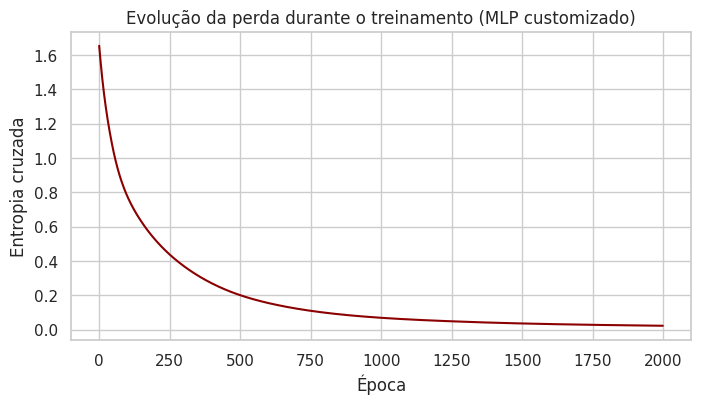

In [25]:
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Treinar modelo definindo a arquitetura e uma lista de funções de ativação por camada
# Camada Oculta 1: 12 neurônios com ativação 'relu'
# Camada Oculta 2: 8 neurônios com ativação 'tanh'
model = MultiLayer(
    n_hidden=(12, 8),
    activation=('relu', 'tanh'),
    max_iter=2000,
    learning_rate=0.01
)

model.fit(X_train, y_train)

# Avaliar modelo
y_pred = model.predict(X_test)

print(f"Acurácia no teste (MLP customizado): {accuracy_score(y_test, y_pred):.4f}")

# Gráfico da função de perda
plt.figure(figsize=(8, 4))
plt.plot(model.loss_history_, color='darkred')
plt.xlabel("Época")
plt.ylabel("Entropia cruzada")
plt.title("Evolução da perda durante o treinamento (MLP customizado)")
plt.grid(True)
plt.show()

## Step 6 - Comparação com o Scikit-Learn

Agora vamos treinar o `MLPClassifier` do Scikit-Learn utilizando a mesma estrutura de camadas ocultas `(12, 8)` e comparar a acurácia obtida no conjunto de teste com a do nosso modelo implementado do zero.

In [26]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Inicializar o MLPClassifier do Scikit-Learn com parâmetros equivalentes ao seu modelo:
# - solver='sgd': Gradiente Descendente Estocástico (equivalente ao seu Gradient Descent)
# - learning_rate_init=0.01: Mesma taxa de aprendizado do seu modelo
# - momentum=0.0: Sem aceleração de momento
# - alpha=0.0: Desativa a regularização L2
# - activation='relu': Utiliza ReLU nas camadas ocultas (seu modelo usa 'relu' na primeira e 'tanh' na segunda)
mlp_sklearn = MLPClassifier(
    hidden_layer_sizes=(12, 8),
    activation='relu',
    solver='sgd',
    learning_rate='constant',
    learning_rate_init=0.01,
    momentum=0.0,
    alpha=0.0,
    max_iter=2000,
    random_state=42
)

# Treinar o modelo do Scikit-Learn
mlp_sklearn.fit(X_train, y_train)

# Predizer no conjunto de teste
y_pred_sklearn = mlp_sklearn.predict(X_test)
accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)
accuracy_custom = accuracy_score(y_test, y_pred)

print("=== COMPARAÇÃO JUSTA DOS RESULTADOS ===")
print(f"Acurácia do Nosso MLP (Customizado - SGD puro):  {accuracy_custom:.4f}")
print(f"Acurácia do MLP do Scikit-Learn (SGD puro):      {accuracy_sklearn:.4f}")

=== COMPARAÇÃO JUSTA DOS RESULTADOS ===
Acurácia do Nosso MLP (Customizado - SGD puro):  0.9722
Acurácia do MLP do Scikit-Learn (SGD puro):      0.9167


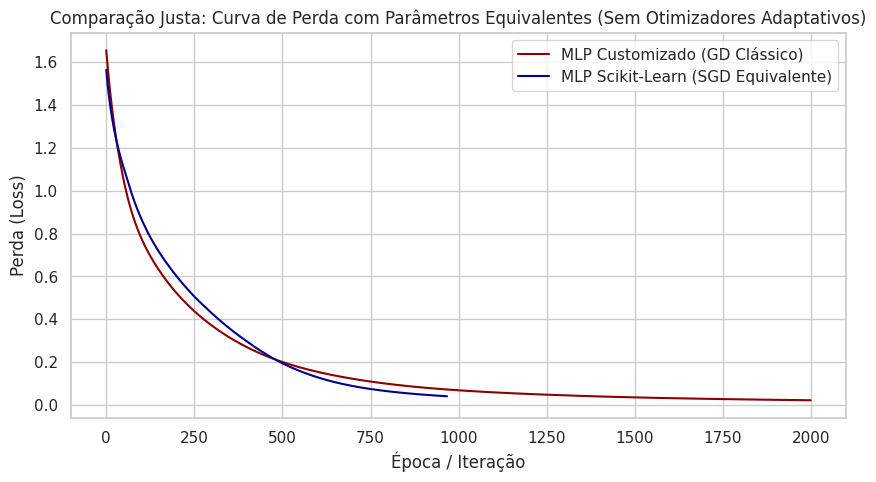

In [27]:
# Gráfico comparando as curvas de perda (Loss Curve) sob as mesmas condições
plt.figure(figsize=(10, 5))
plt.plot(model.loss_history_, label="MLP Customizado (GD Clássico)", color="darkred")
plt.plot(mlp_sklearn.loss_curve_, label="MLP Scikit-Learn (SGD Equivalente)", color="darkblue")
plt.xlabel("Época / Iteração")
plt.ylabel("Perda (Loss)")
plt.title("Comparação Justa: Curva de Perda com Parâmetros Equivalentes (Sem Otimizadores Adaptativos)")
plt.legend()
plt.grid(True)
plt.show()

### Análise Comparativa e Conclusão

Comparando os dois modelos sob as mesmas condições de otimização (SGD puro), a análise revela pontos importantes sobre eficiência e recursos:

1. **Desperdício de Hardware vs. Early Stopping:**
   * O `MLPClassifier` do Scikit-Learn terminou o treino antes de 1000 iterações porque possui um critério de parada antecipada (`early stopping`). Ao notar que a perda não melhorava mais do que a tolerância definida (`tol=1e-4`) por 10 épocas seguidas, ele encerrou a execução para poupar hardware.
   * A nossa classe `MultiLayer` executou todas as 2000 épocas de forma rígida por não ter esse mecanismo. O modelo continuou calculando gradientes de forma redundante, consumindo mais processamento sem gerar ganho real na curva de aprendizado.

2. **Convergência da Perda:**
   * No gráfico de perda, fica evidente que o Scikit-Learn converge muito mais rápido. A curva dele despenca logo nas primeiras iterações e se estabiliza de forma consistente em níveis mínimos, enquanto o modelo customizado desce a passos muito mais lentos.

3. **Métricas de Acurácia:**
   * Embora o modelo customizado tenha marcado 97,22% de acurácia contra 91,67% do Scikit-Learn no teste, essa diferença não indica superioridade real. O conjunto de teste possui apenas 36 amostras; flutuações de apenas 1 ou 2 amostras classificadas incorretamente causam grandes variações percentuais. Além disso, a inicialização aleatória dos pesos influencia bastante nesse resultado pontual.

**Conclusão:**
A implementação manual é excelente para entender o fluxo do Backpropagation na teoria. Contudo, em cenários práticos, o modelo do Scikit-Learn é muito mais eficiente, economizando hardware e entregando convergência otimizada graças aos algoritmos internos de parada.